<a href="https://colab.research.google.com/github/yeyevtushenko/High-performance-distributed-computing-systems/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%965.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['figure.figsize'] = (13.0, 5.0)

# Завдання 1. Лінійна регресія для врожайності яблук та апельсинів

> Натренуйте модель лінійної регресії надану в теоретичному описі (для аналізу врожайності яблук та апельсинів) деяку кількість епох. Подивіться як змінюються ваги та похибка (втрати). Знайдіть оптимальну кількість епох для тренування. Порахуйте MSE та зробіть висновки щодо оптимальної кількості епох та отриманих результатів.

## Дані та модель

In [ ]:
inputs = np.array([[73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70]], dtype='float32')

targets = np.array([[56, 70],
                    [81, 101],
                    [119, 133],
                    [22, 37],
                    [103, 119]], dtype='float32')

inputs = torch.from_numpy(inputs)
targets = torch.from_numpy(targets)

print(inputs.shape, targets.shape)

torch.Size([5, 3]) torch.Size([5, 2])


Вхідні змінні це температура, кількість опадів і вологість, а цільові змінні це врожайність яблук і апельсинів у п'яти регіонах.

In [ ]:
torch.manual_seed(42)
w = torch.randn(2, 3, requires_grad=True)
b = torch.randn(2, requires_grad=True)

def model(x):
    return x @ w.t() + b

def mse(t1, t2):
    diff = t1 - t2
    return torch.sum(diff * diff) / diff.numel()

w_start = w.detach().clone()
b_start = b.detach().clone()

preds = model(inputs)
print(preds)
print(targets)
print("MSE до навчання:", mse(preds, targets).item())

tensor([[  45.4987,  -67.0672],
        [  59.1878,  -90.4141],
        [  62.3595, -141.8688],
        [  50.7645,  -32.3210],
        [  54.2179, -105.5822]], grad_fn=<AddBackward0>)
tensor([[ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.]])
MSE до навчання: 19322.34765625


Ваги та зміщення задано випадково, тому прогнози сильно відрізняються від цілей, а початкова втрата дуже велика.

## Тренування моделі

In [ ]:
EPOCHS = 10000
LEARNING_RATE = 1e-5

loss_history = []
w_history = []
b_history = []

for epoch in range(EPOCHS + 1):
    preds = model(inputs)
    loss = mse(preds, targets)

    loss_history.append(loss.item())
    w_history.append(w.detach().numpy().copy())
    b_history.append(b.detach().numpy().copy())

    loss.backward()
    with torch.no_grad():
        w -= w.grad * LEARNING_RATE
        b -= b.grad * LEARNING_RATE
        w.grad.zero_()
        b.grad.zero_()

loss_history = np.array(loss_history)
w_history = np.array(w_history)
b_history = np.array(b_history)

print("Початкова втрата:", loss_history[0])
print("Кінцева втрата:  ", loss_history[-1])

Початкова втрата: 19322.34765625
Кінцева втрата:   0.5537793040275574


На кожній епосі виконується п'ять кроків із теорії: прогноз, обчислення втрат, обчислення градієнтів, оновлення ваг пропорційно градієнту та обнулення градієнтів. Швидкість навчання дорівнює `1e-5`. Епоха 0 відповідає моделі до навчання.

## Як змінюються ваги та втрати

In [ ]:
checkpoints = [0, 1, 10, 50, 100, 500, 1000, 2000, 5000, 10000]

table = pd.DataFrame({
    'loss (MSE)': loss_history[checkpoints],
    'w11': w_history[checkpoints, 0, 0],
    'w12': w_history[checkpoints, 0, 1],
    'w13': w_history[checkpoints, 0, 2],
    'b1': b_history[checkpoints, 0],
    'w21': w_history[checkpoints, 1, 0],
    'w22': w_history[checkpoints, 1, 1],
    'w23': w_history[checkpoints, 1, 2],
    'b2': b_history[checkpoints, 1],
}, index=pd.Index(checkpoints, name='epoch'))

print(table.round(4).to_string())

       loss (MSE)     w11     w12     w13      b1     w21     w22     w23      b2
epoch                                                                            
0      19322.3477  0.3367  0.1288  0.2345  2.2082  0.2303 -1.1229 -0.1863 -0.6380
1      13438.3047  0.3529  0.1561  0.2494  2.2084  0.3781 -0.9481 -0.0816 -0.6362
10      1520.6101  0.3893  0.2814  0.3103  2.2091  0.8999 -0.2479  0.3233 -0.6297
50       709.9987  0.2335  0.4428  0.3488  2.2081  0.7425  0.1154  0.4459 -0.6301
100      380.8443  0.0707  0.5768  0.3772  2.2070  0.4796  0.3334  0.4894 -0.6319
500        7.9174 -0.3420  0.8876  0.4961  2.2044 -0.1844  0.8431  0.6651 -0.6360
1000       2.5512 -0.3897  0.8901  0.5642  2.2043 -0.2584  0.8526  0.7615 -0.6360
2000       0.8618 -0.4070  0.8652  0.6303  2.2043 -0.2830  0.8180  0.8545 -0.6357
5000       0.5550 -0.4166  0.8494  0.6705  2.2036 -0.2965  0.7957  0.9110 -0.6359
10000      0.5538 -0.4172  0.8484  0.6731  2.2024 -0.2974  0.7943  0.9146 -0.6365


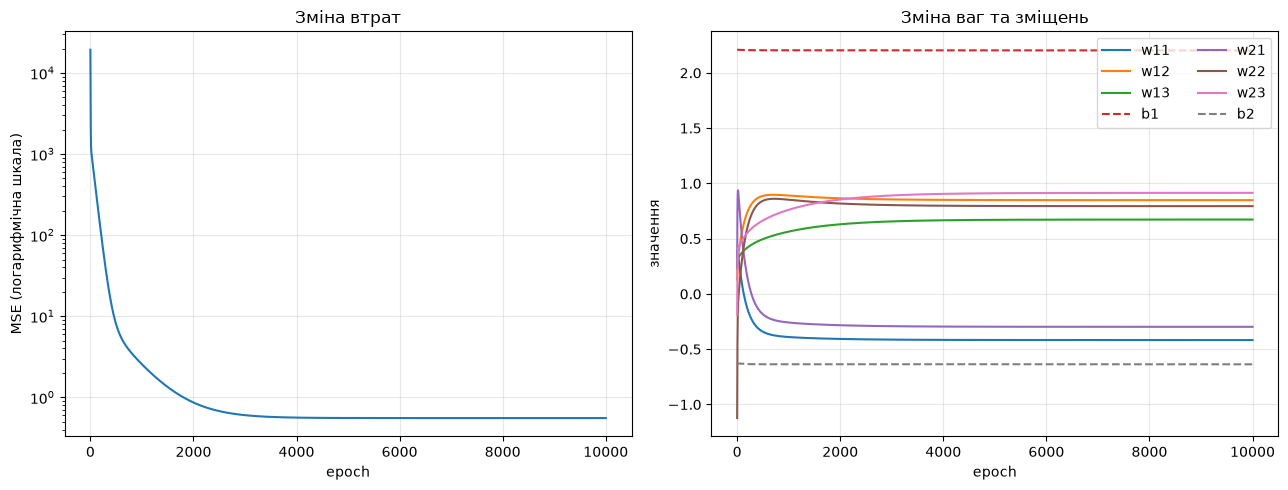

In [ ]:
fig, axes = plt.subplots(1, 2)

axes[0].semilogy(loss_history)
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('MSE (логарифмічна шкала)')
axes[0].set_title('Зміна втрат')
axes[0].grid(alpha=0.3)

for i in range(2):
    for j in range(3):
        axes[1].plot(w_history[:, i, j], label=f'w{i + 1}{j + 1}')
    axes[1].plot(b_history[:, i], '--', label=f'b{i + 1}')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('значення')
axes[1].set_title('Зміна ваг та зміщень')
axes[1].legend(ncol=2)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Пошук оптимальної кількості епох

In [ ]:
WINDOW = 100

def first_plateau_epoch(threshold):
    for epoch in range(WINDOW, len(loss_history)):
        relative_gain = (loss_history[epoch - WINDOW] - loss_history[epoch]) / loss_history[epoch - WINDOW]
        if relative_gain < threshold:
            return epoch
    return len(loss_history) - 1

for threshold in (0.05, 0.01, 0.001):
    epoch = first_plateau_epoch(threshold)
    print(f"Покращення втрат за {WINDOW} епох менше {threshold:.1%}: епоха {epoch}, MSE = {loss_history[epoch]:.4f}")

Покращення втрат за 100 епох менше 5.0%: епоха 2257, MSE = 0.7444
Покращення втрат за 100 епох менше 1.0%: епоха 3272, MSE = 0.5825
Покращення втрат за 100 епох менше 0.1%: епоха 4534, MSE = 0.5565


Тестової вибірки в завданні немає, тому оптимальна кількість епох визначається за моментом, коли втрати майже перестають зменшуватись: покращення втрат за останні 100 епох стає меншим за обраний поріг.

In [ ]:
X_design = torch.cat([inputs, torch.ones(inputs.shape[0], 1)], dim=1)
best_solution = torch.linalg.lstsq(X_design, targets).solution
best_loss = mse(X_design @ best_solution, targets).item()

optimal_epoch = first_plateau_epoch(0.01)

print("Найменша можлива MSE для лінійної моделі:", round(best_loss, 4))
print("Обрана кількість епох:", optimal_epoch)
print("MSE на обраній епосі:", round(loss_history[optimal_epoch], 4))
print("MSE після", EPOCHS, "епох:", round(loss_history[-1], 4))

Найменша можлива MSE для лінійної моделі: 0.4831
Обрана кількість епох: 3272
MSE на обраній епосі: 0.5825
MSE після 10000 епох: 0.5538


Для порівняння обчислено найменшу MSE, яку взагалі може дати лінійна модель на цих даних (розв'язок методом найменших квадратів). Вона показує, наскільки близько градієнтний спуск підійшов до межі.

## MSE та прогнози після навчання

In [ ]:
w_opt = torch.from_numpy(w_history[optimal_epoch])
b_opt = torch.from_numpy(b_history[optimal_epoch])
preds_opt = inputs @ w_opt.t() + b_opt

print("Прогнози на епосі", optimal_epoch)
print(preds_opt)
print("Цілі")
print(targets)
print("MSE:", mse(preds_opt, targets).item())
print("RMSE:", mse(preds_opt, targets).sqrt().item())

Прогнози на епосі 3272
tensor([[ 57.5457,  70.2189],
        [ 81.8778, 100.5995],
        [118.8366, 133.2621],
        [ 21.0920,  37.1089],
        [101.7763, 118.8348]])
Цілі
tensor([[ 56.,  70.],
        [ 81., 101.],
        [119., 133.],
        [ 22.,  37.],
        [103., 119.]])
MSE: 0.5824602246284485
RMSE: 0.7631908059120178


# Висновки

У цьому практикумі ми навчились реалізовувати градієнтний спуск у PyTorch та використовувати його для навчання моделі лінійної регресії, яка прогнозує врожайність яблук і апельсинів. Метою завдання було ознайомитись з механізмом градієнтного спуску та навчитися його програмній реалізації у PyTorch, і її досягнуто.

**Базовий принцип роботи градієнтного спуску.** Змінні, за якими потрібно оптимізувати функцію, створюються з `requires_grad=True`. Метод `backward` обчислює похідну функції втрат за кожною такою змінною, рухаючись від останньої операції до аргументу, і записує результат у `.grad`. Градієнт показує швидкість і напрямок зміни втрат, тому на кожному кроці змінна зменшується на добуток градієнта та швидкості навчання. Потім градієнти обнуляються методом `zero_()`, бо PyTorch їх накопичує. Одна ітерація навчання моделі складається з п'яти кроків: прогноз, обчислення втрат, обчислення градієнтів, оновлення ваг та зміщень і скидання градієнтів.

**Результати аналізу моделі лінійної регресії.** Модель навчалась 10 000 епох зі швидкістю навчання `1e-5`, а втрати вимірювались як середня квадратична помилка (MSE).
- Початкові випадкові ваги дали MSE 19322.35. Після 10 епох втрати впали до 1520.61, після 100 до 380.84, після 500 до 7.92, після 1000 до 2.55, після 2000 до 0.86, а після 5000 епох до 0.5550. Далі зміна майже припинилась: після 10 000 епох MSE становить 0.5538.
- Найшвидше втрати зменшуються на початку навчання, коли градієнти великі, а далі кроки стають дедалі меншими, бо градієнт наближається до нуля. Крива втрат на логарифмічній шкалі спадає майже прямою лінією, тобто швидкість зменшення близька до експоненціальної.
- Ваги змінюються в тому самому ритмі: основні зміни відбуваються за перші 500 епох, а далі вони лише дрібно підлаштовуються. Наприклад, `w22` змінилась з -1.12 до 0.79, а `w12` з 0.13 до 0.85. Зміщення майже не змінились (`b1` з 2.21 до 2.20, `b2` з -0.64 до -0.64), бо їхні градієнти малі порівняно з градієнтами ваг при вхідних значеннях порядку сотень.
- Для порівняння, найменша MSE, яку лінійна модель може отримати на цих п'яти спостереженнях, становить 0.4831. Градієнтний спуск підійшов до неї на 0.5538.

**Оптимальна кількість епох.** Тестової вибірки в завданні немає, тому оптимум визначався за моментом, коли втрати майже перестають зменшуватись. Покращення втрат за 100 епох стає меншим за 5% на епосі 2257 (MSE 0.7444), меншим за 1% на епосі 3272 (MSE 0.5825) і меншим за 0.1% на епосі 4534 (MSE 0.5565). Як оптимальну обрано 3272 епохи, бо далі додаткові тисячі епох дають лише соті частки одиниці MSE. На цій епосі MSE дорівнює 0.5825, RMSE дорівнює 0.76 тонни, а прогнози відхиляються від цілей не більше ніж на 1.6 тонни (наприклад, 57.5 проти 56 і 101.8 проти 103). Менша кількість епох, наприклад 500, залишає помилку значно більшою, а більша, наприклад 10 000, лише на кілька відсотків краща за обрану.

**Обмеження.** Модель навчалась і оцінювалась на тих самих п'яти спостереженнях, тому отримана MSE показує якість підгонки до навчальних даних, а не якість прогнозів для нових регіонів.

# Контрольні питання

**1. Що являє собою градієнтний спуск?**

Градієнтний спуск це ітеративний метод оптимізації, який зменшує значення функції (наприклад, функції втрат) невеликими кроками в напрямку, протилежному градієнту. Градієнт це похідна функції за її змінними, і він показує швидкість зміни функції або її нахил. У PyTorch змінну позначають `requires_grad=True`, складають із неї функцію, після чого метод `backward` обчислює похідні, повертаючись від останньої операції до аргументу, а результат з'являється в атрибуті `.grad`. Далі значення змінної зменшують на добуток градієнта та швидкості навчання, а градієнти обнуляють, бо в PyTorch вони накопичуються.

**2. Як змінюються ваги при роботі градієнтного спуску?**

На кожному кроці від ваги віднімається невелика величина, пропорційна її градієнту: `w = w - lr * w.grad`, де `lr` це швидкість навчання. Якщо градієнт елемента позитивний, то зменшення ваги трохи зменшить втрати, а якщо негативний, то втрати зменшить її збільшення. Тому ваги рухаються в бік, де втрати менші, а чим менший градієнт, тим менші кроки. Оновлення виконують без відстеження градієнтів (`torch.no_grad()` або `x.data`), а після нього градієнти скидають до нуля методом `zero_()`.